# 📈 Day 01 – Seasonal Naive Forecasting

## 1. Objective

The **Seasonal Naive method** forecasts future values by repeating the values from the most recently observed seasonal cycle.

It is useful when a time series has a recurring seasonal pattern, such as weekly demand patterns or higher sales during particular months.

## 2. Mathematical formula

Let `m` be the number of observations in one complete seasonal cycle.

For the first seasonal cycle ahead, copy the values from the latest observed cycle:

$$
\hat{y}_{T+h\mid T} = y_{T+h-m},
\qquad h = 1, 2, \ldots, m
$$

If the forecast horizon is longer than one seasonal cycle, repeat the forecast pattern:

$$
\hat{y}_{T+h\mid T} = \hat{y}_{T+h-m\mid T},
\qquad h > m
$$

**Notation**
- `y_T`: actual value observed at the forecast origin `T`.
- `ŷ_(T+h | T)`: forecast for time `T+h`, using information available up to time `T`.
- `m`: seasonal period (number of observations in one season).
- `h`: forecast horizon.

**Example:** For monthly data with `m = 12`, the forecast for January is the actual value from the previous January, February uses the previous February, and so on. If forecasting more than 12 months ahead, the same 12-month pattern repeats.

This recursive form is often easier to read than a formula involving ceiling notation.

## 3. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

## 4. Create a sample seasonal time series

We will generate 72 months of synthetic demand. The data contains:
- A gradual upward trend.
- A repeating 12-month seasonal pattern.
- Random noise.

The seasonal period for monthly data with yearly seasonality is `m = 12`.

In [2]:
np.random.seed(42)

dates = pd.date_range(start="2020-01-01", periods=72, freq="MS")
time_index = np.arange(len(dates))

# A repeating annual pattern: demand tends to rise in some months and fall in others.
seasonal_pattern = np.array([ -18, -12, -5, 2, 8, 14, 18, 15, 7, 0, 10, 25 ])

demand = (
    150
    + 1.0 * time_index
    + np.tile(seasonal_pattern, 6)
    + np.random.normal(loc=0, scale=5, size=len(dates))
)

df = pd.DataFrame({
    "Date": dates,
    "Demand": demand
})

df.head()

,Date,Demand
0,2020-01-01,134.483571
1,2020-02-01,138.308678
2,2020-03-01,150.238443
3,2020-04-01,162.615149
4,2020-05-01,160.829233


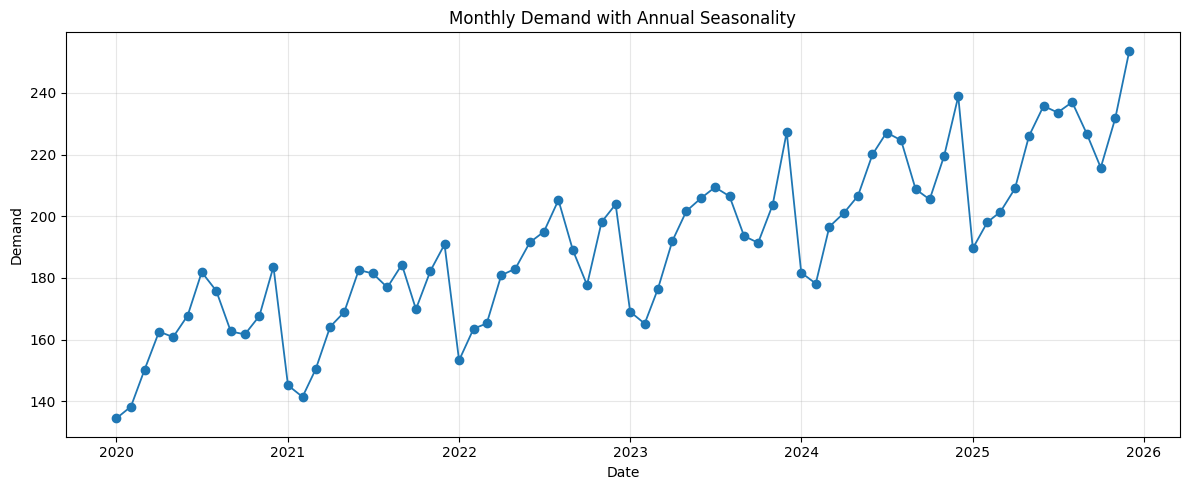

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Demand"], marker="o", linewidth=1.3)
plt.title("Monthly Demand with Annual Seasonality")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Set the seasonal period and split the data

For this example:
- Frequency: Monthly
- Seasonal period (`m`): 12
- Forecast horizon: 12 months

We hold out the final 12 months as the test set. The training data therefore contains six complete years of observations.

In [4]:
seasonal_period = 12
forecast_horizon = 12

train = df.iloc[:-forecast_horizon].copy()
test = df.iloc[-forecast_horizon:].copy()

if len(train) < seasonal_period:
    raise ValueError("Training data must contain at least one complete seasonal cycle.")

print(f"Training observations: {len(train)}")
print(f"Test observations: {len(test)}")
print(f"Seasonal period: {seasonal_period}")
print(f"Training period: {train['Date'].min().date()} to {train['Date'].max().date()}")
print(f"Test period: {test['Date'].min().date()} to {test['Date'].max().date()}")

Training observations: 60
Test observations: 12
Seasonal period: 12
Training period: 2020-01-01 to 2024-12-01
Test period: 2025-01-01 to 2025-12-01


## 6. Generate the Seasonal Naive forecast

Take the **last complete seasonal cycle** from the training data and repeat it until the forecast horizon is filled.

For monthly data with `m = 12`, this means using the last 12 observed training values as the forecast pattern.

Crucially, the pattern comes from the training set only. Test-set actuals must not be used to generate the forecast.

In [5]:
last_season = train["Demand"].iloc[-seasonal_period:].to_numpy()

# Repeat the last observed seasonal cycle to cover the requested horizon.
seasonal_forecast = np.tile(
    last_season,
    int(np.ceil(forecast_horizon / seasonal_period))
)[:forecast_horizon]

results = test[["Date", "Demand"]].copy()
results["Seasonal_Naive_Forecast"] = seasonal_forecast

print("Last observed seasonal cycle:")
print(last_season)
results

Last observed seasonal cycle:
[181.71809145 178.18479922 196.62041985 201.0745886  206.61539
 220.05838144 227.15499761 224.6564006  208.80391238 205.45393812
 219.65631716 238.87772564]


,Date,Demand,Seasonal_Naive_Forecast
60,2025-01-01,189.604129,181.718091
61,2025-02-01,198.071705,178.184799
62,2025-03-01,201.468325,196.620420
63,2025-04-01,209.018967,201.074589
64,2025-05-01,226.062629,206.615390
65,2025-06-01,235.781200,220.058381
66,2025-07-01,233.639949,227.154998
67,2025-08-01,237.017664,224.656401
68,2025-09-01,226.808180,208.803912
69,2025-10-01,215.774401,205.453938


## 7. Visualize actual vs forecast

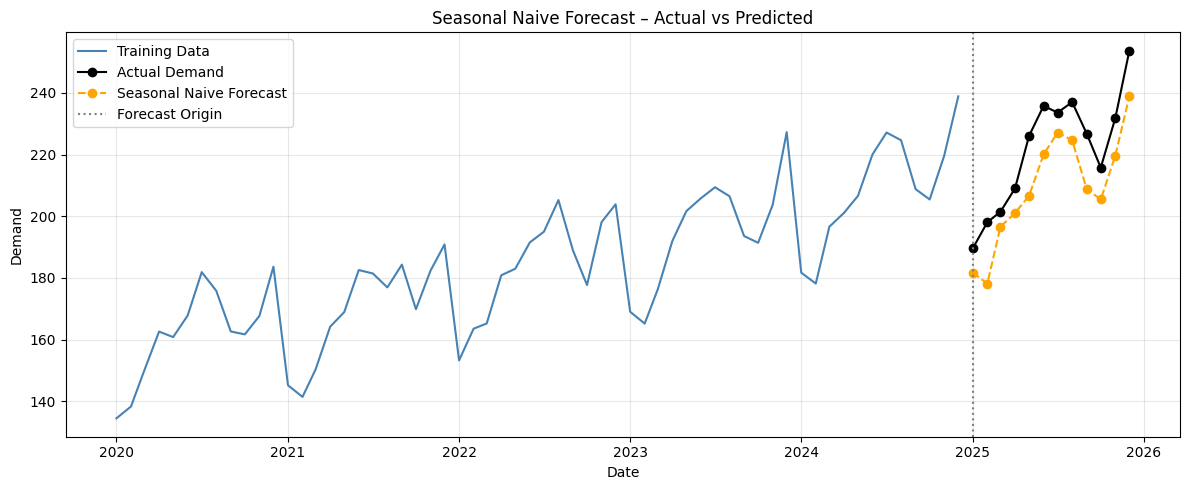

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(train["Date"], train["Demand"], label="Training Data", color="steelblue")
plt.plot(test["Date"], test["Demand"], label="Actual Demand", marker="o", color="black")
plt.plot(test["Date"], results["Seasonal_Naive_Forecast"],
         label="Seasonal Naive Forecast", linestyle="--", marker="o", color="orange")

plt.axvline(test["Date"].iloc[0], color="gray", linestyle=":", label="Forecast Origin")
plt.title("Seasonal Naive Forecast – Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluate forecast accuracy

We will calculate MAE, RMSE, MAPE, and WMAPE. Lower values indicate better accuracy for these error metrics.

- **MAE:** Average absolute error.
- **RMSE:** Gives more weight to large errors.
- **MAPE:** Percentage error; undefined when actual values are zero.
- **WMAPE:** Total absolute error divided by total absolute actual demand.

In [7]:
actual = results["Demand"].to_numpy()
predicted = results["Seasonal_Naive_Forecast"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

nonzero_mask = actual != 0
mape = (
    np.mean(np.abs((actual[nonzero_mask] - predicted[nonzero_mask]) / actual[nonzero_mask])) * 100
    if nonzero_mask.any()
    else np.nan
)

denominator = np.sum(np.abs(actual))
wmape = (
    np.sum(np.abs(actual - predicted)) / denominator * 100
    if denominator != 0
    else np.nan
)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "WMAPE (%)"],
    "Value": [mae, rmse, mape, wmape]
})

metrics

,Metric,Value
0,MAE,12.489112
1,RMSE,13.423439
2,MAPE (%),5.622507
3,WMAPE (%),5.636847


## 9. Inspect forecast errors

In [8]:
results["Error"] = results["Seasonal_Naive_Forecast"] - results["Demand"]
results["Absolute_Error"] = results["Error"].abs()
results

,Date,Demand,Seasonal_Naive_Forecast,Error,Absolute_Error
60,2025-01-01,189.604129,181.718091,-7.886037,7.886037
61,2025-02-01,198.071705,178.184799,-19.886906,19.886906
62,2025-03-01,201.468325,196.620420,-4.847905,4.847905
63,2025-04-01,209.018967,201.074589,-7.944378,7.944378
64,2025-05-01,226.062629,206.615390,-19.447239,19.447239
65,2025-06-01,235.781200,220.058381,-15.722819,15.722819
66,2025-07-01,233.639949,227.154998,-6.484952,6.484952
67,2025-08-01,237.017664,224.656401,-12.361264,12.361264
68,2025-09-01,226.808180,208.803912,-18.004268,18.004268
69,2025-10-01,215.774401,205.453938,-10.320463,10.320463


## 10. Interpretation

- The Seasonal Naive method preserves the seasonal pattern from the latest observed cycle.
- It does not estimate or extend the trend. If the level of demand has changed, the repeated seasonal values may be too high or too low.
- Its performance depends on choosing an appropriate seasonal period.
- It is often a stronger baseline than the basic Naive method when seasonality is stable.

## 11. Choosing the seasonal period

The seasonal period depends on the data frequency and the business cycle you want to capture. Common examples include:

| Data frequency | Possible seasonal period (`m`) |
|---|---:|
| Hourly data with daily seasonality | 24 |
| Daily data with weekly seasonality | 7 |
| Weekly data with annual seasonality | 52 (approximate) |
| Monthly data with annual seasonality | 12 |
| Quarterly data with annual seasonality | 4 |

These are common choices, not universal rules. Consider the actual business calendar and data characteristics. For example, weekly data can have 52 or 53 weeks in a calendar year.

## 12. Advantages and limitations

**Advantages**
- Simple to implement and explain.
- Captures recurring seasonal patterns.
- Useful as a benchmark for seasonal demand.

**Limitations**
- Assumes the seasonal pattern repeats.
- Does not model trend or changes in seasonality.
- Sensitive to unusual values in the most recent seasonal cycle.
- Requires a sensible seasonal period and enough historical observations.

## 13. Practical use cases

- Retail demand with recurring monthly or weekly patterns.
- Energy consumption with daily or weekly seasonality.
- Product sales that repeat a yearly seasonal pattern.
- Baseline forecasts before using models such as Holt-Winters, SARIMA, or machine-learning methods.

## 14. Key takeaway

Seasonal Naive is a strong baseline when seasonality is present and reasonably stable. It repeats the latest observed seasonal cycle; it does not learn the trend or explain why the pattern occurs.